In [1]:
import numpy as np
import pandas as pd
import scipy
import scanpy as sc
import anndata as ad

/opt/conda/envs/bipca-experiment/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [27]:
from sklearn.metrics import balanced_accuracy_score

# load data

In [2]:
micro_counts = scipy.io.mmread("../01-Regional_data_processing/combined/data/seurat_micro_counts.txt")

In [3]:
micro_genes = pd.read_csv("../01-Regional_data_processing/combined/data/seurat_micro_genes.csv",index_col=0)

In [4]:
micro_meta = pd.read_csv("../01-Regional_data_processing/combined/data/seurat_micro_meta.csv",index_col=0)

In [5]:
micro_sc = sc.AnnData(X = micro_counts.T.toarray(),obs=micro_meta)
micro_sc.var_names = micro_genes['x'].values

In [6]:
micro_sc

AnnData object with n_obs × n_vars = 42536 × 35574
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'sample_name', 'sample_ids', 'region', 'condition_new', 'consensus_cell_type_coarse', 'consensus_cell_type_coarse_l1', 'consensus_annotation_v2', 'consensus_annotation_v3'

# preprocess scorch data

1. data normalization 2. label conversion 3. data splitting

In [7]:
from sklearn.linear_model import LogisticRegression

import bipca


In [8]:
from bipca.experiments.normalizations import log1p

/opt/conda/envs/bipca-experiment/lib/python3.10/site-packages/umap/distances.py:1063: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/opt/conda/envs/bipca-experiment/lib/python3.10/site-packages/umap/distances.py:1071: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/opt/conda/envs/bipca-experiment/lib/python3.10/site-packages/umap/distanc

In [9]:
micro_sc.layers['log1p'] = log1p(micro_sc.X)

In [10]:
np.unique(micro_sc.obs['condition_new'])

array(['CTR', 'HIV'], dtype=object)

In [11]:
micro_label_converter = {"HIV":1,"CTR":0}
micro_sc.obs['y'] = np.array([micro_label_converter[condition] for condition in micro_sc.obs['condition_new']])

In [12]:
micro_sc

AnnData object with n_obs × n_vars = 42536 × 35574
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'sample_name', 'sample_ids', 'region', 'condition_new', 'consensus_cell_type_coarse', 'consensus_cell_type_coarse_l1', 'consensus_annotation_v2', 'consensus_annotation_v3', 'y'
    layers: 'log1p'

In [13]:
# split by regions
micro_sc_pfc = micro_sc[micro_sc.obs['region'] == "PFC",:]
micro_sc_ins = micro_sc[micro_sc.obs['region'] == "INS",:]
micro_sc_vst = micro_sc[micro_sc.obs['region'] == "VST",:]


# lasso within scorch data

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [15]:
X_pfc = micro_sc_pfc.layers['log1p']
y_pfc = micro_sc_pfc.obs['y'].values

X_ins = micro_sc_ins.layers['log1p']
y_ins = micro_sc_ins.obs['y'].values

X_vst = micro_sc_vst.layers['log1p']
y_vst = micro_sc_vst.obs['y'].values


# first only within ins

In [ ]:
# 5 fold cross validation (each fold is stratified by samples), and test on the remaining samples



In [20]:
c_grid = np.logspace(-3,1,10)

In [21]:
test_sample_ids = ['HCTTS','1068','HCCRS','HCTMW','7200776574','10305',]
kfold_idx_dict = {0:['10280','HCCCY','7101847783','HCTMU','7102096765'],
                 1: ['1039','HCTME','HCTPK','HCTNZ','10304','7100518287'],
                 2: ["1133",'HCTXJ','6801066772','1040'],
                 3: [ '1059','1181','1119','HCTGD'],
                 4: ['HCCPL','1137','6801187468','10288','HCTKN','1048']}

In [23]:
train_set_sample_ids = np.hstack(kfold_idx_dict.values())

/tmp/ipykernel_51946/3435480060.py:1: FutureWarning: arrays to stack must be passed as a "sequence" type such as list or tuple. Support for non-sequence iterables such as generators is deprecated as of NumPy 1.16 and will raise an error in the future.
  train_set_sample_ids = np.hstack(kfold_idx_dict.values())


In [24]:
kfold_val_acc = {c:{i:np.nan for i in range(5)} for c in c_grid}
n_selected_feats = {c:{i:np.nan for i in range(5)} for c in c_grid}

In [25]:
top_n

2000

In [28]:
for c in c_grid:
    print("----------------------")
    print("current c: {} ".format(c))
    for k_idx in range(5):
        print(">>>>>>>>>>>>>>>>>")
        validation_id_set = kfold_idx_dict[k_idx]
        training_id_set = train_set_sample_ids[[sid not in validation_id_set for sid in train_set_sample_ids]]
        val_token = np.array([sid in validation_id_set for sid in micro_sc_ins.obs['sample_ids']])
        train_token = np.array([sid in training_id_set for sid in micro_sc_ins.obs['sample_ids']])

        X_train, X_val, y_train, y_val = X_ins[train_token,:],X_ins[val_token,:], y_ins[train_token] ,y_ins[val_token]

        # keep the top variable genes
        top_n = 2000
        top_var_feats_idx = np.argsort(np.std(X_train,axis=0))[::-1][:top_n]
        X_train = X_train[:,top_var_feats_idx]
        X_val = X_val[:,top_var_feats_idx]

        scaler = StandardScaler()
        scaler.fit(X_train)
        X_train_z = scaler.transform(X_train)
        X_val_z = scaler.transform(X_val)

        clf = LogisticRegression(random_state=0,penalty='l1',C=c,solver= 'liblinear').fit(X_train_z, y_train)
        y_pred = clf.predict(X_val_z)   
        
        kfold_val_acc[c][k_idx] = balanced_accuracy_score(y_val,y_pred)
        n_selected_feats[c][k_idx] = np.sum(clf.coef_.reshape(-1) !=0)
        print("current k_idx: {}, val_acc: {:.4f}, n_feats: {}".format(k_idx,kfold_val_acc[c][k_idx],n_selected_feats[c][k_idx]))

----------------------
current c: 0.001 
>>>>>>>>>>>>>>>>>
current k_idx: 0, val_acc: 0.6724, n_feats: 15
>>>>>>>>>>>>>>>>>
current k_idx: 1, val_acc: 0.5474, n_feats: 5
>>>>>>>>>>>>>>>>>


/opt/conda/envs/bipca-experiment/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


current k_idx: 2, val_acc: 0.8191, n_feats: 7
>>>>>>>>>>>>>>>>>
current k_idx: 3, val_acc: 0.7806, n_feats: 7
>>>>>>>>>>>>>>>>>
current k_idx: 4, val_acc: 0.8230, n_feats: 9
----------------------
current c: 0.0027825594022071257 
>>>>>>>>>>>>>>>>>
current k_idx: 0, val_acc: 0.6020, n_feats: 46
>>>>>>>>>>>>>>>>>
current k_idx: 1, val_acc: 0.8488, n_feats: 27
>>>>>>>>>>>>>>>>>


/opt/conda/envs/bipca-experiment/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


current k_idx: 2, val_acc: 0.8967, n_feats: 37
>>>>>>>>>>>>>>>>>
current k_idx: 3, val_acc: 0.8800, n_feats: 31
>>>>>>>>>>>>>>>>>
current k_idx: 4, val_acc: 0.8638, n_feats: 42
----------------------
current c: 0.007742636826811269 
>>>>>>>>>>>>>>>>>
current k_idx: 0, val_acc: 0.5832, n_feats: 87
>>>>>>>>>>>>>>>>>
current k_idx: 1, val_acc: 0.8941, n_feats: 76
>>>>>>>>>>>>>>>>>


...

current k_idx: 2, val_acc: 0.9038, n_feats: 645
>>>>>>>>>>>>>>>>>
current k_idx: 3, val_acc: 0.9365, n_feats: 599
>>>>>>>>>>>>>>>>>
current k_idx: 4, val_acc: 0.9243, n_feats: 545
----------------------
current c: 3.593813663804626 
>>>>>>>>>>>>>>>>>
current k_idx: 0, val_acc: 0.5793, n_feats: 690
>>>>>>>>>>>>>>>>>
current k_idx: 1, val_acc: 0.9222, n_feats: 678
>>>>>>>>>>>>>>>>>


/opt/conda/envs/bipca-experiment/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


current k_idx: 2, val_acc: 0.9011, n_feats: 744
>>>>>>>>>>>>>>>>>
current k_idx: 3, val_acc: 0.9338, n_feats: 698
>>>>>>>>>>>>>>>>>
current k_idx: 4, val_acc: 0.9257, n_feats: 646
----------------------
current c: 10.0 
>>>>>>>>>>>>>>>>>
current k_idx: 0, val_acc: 0.5867, n_feats: 936
>>>>>>>>>>>>>>>>>
current k_idx: 1, val_acc: 0.9243, n_feats: 915
>>>>>>>>>>>>>>>>>


/opt/conda/envs/bipca-experiment/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


current k_idx: 2, val_acc: 0.8993, n_feats: 902
>>>>>>>>>>>>>>>>>
current k_idx: 3, val_acc: 0.9378, n_feats: 888
>>>>>>>>>>>>>>>>>
current k_idx: 4, val_acc: 0.9234, n_feats: 847


In [29]:
avg_val_accs = np.array([np.mean(list(kfold_val_acc[c].values())) for c in c_grid])

In [30]:
std_val_accs = np.array([np.std(list(kfold_val_acc[c].values())) for c in c_grid])

In [31]:
avg_val_accs

array([0.72850434, 0.8182666 , 0.83867291, 0.85028544, 0.85325588,
       0.85495662, 0.85542911, 0.85319547, 0.85242583, 0.85430891])

In [32]:
median_n_feats = np.array([np.median(list(n_selected_feats[c].values())) for c in c_grid])

In [33]:
median_n_feats

array([  7.,  37.,  85., 166., 281., 428., 522., 599., 690., 902.])

In [34]:
best_c = c_grid[np.argmax(avg_val_accs)]

In [35]:
best_c

0.46415888336127775

In [36]:
np.argmax(avg_val_accs)

6

In [196]:
# test on the test set

In [37]:
test_token = np.array([sid in test_sample_ids for sid in micro_sc_ins.obs['sample_ids']])
train_token = ~test_token

In [38]:
X_train, X_test, y_train, y_test = X_ins[train_token,:],X_ins[test_token,:], y_ins[train_token] ,y_ins[test_token]
top_var_feats_idx = np.argsort(np.std(X_train,axis=0))[::-1][:top_n]
X_train = X_train[:,top_var_feats_idx]
X_test = X_test[:,top_var_feats_idx]

scaler = StandardScaler()
scaler.fit(X_train)
X_train_z = scaler.transform(X_train)
X_test_z = scaler.transform(X_test)

clf = LogisticRegression(random_state=0,penalty='l1',C=best_c,solver= 'liblinear').fit(X_train_z, y_train)
y_pred = clf.predict(X_test_z)
balanced_accuracy_score(y_test,y_pred)

0.9898308209278089

In [39]:
y_pred_train = clf.predict(X_train_z)
balanced_accuracy_score(y_train,y_pred_train)

1.0

In [40]:
sum(clf.coef_.reshape(-1) !=0)

642

In [41]:
micro_sc_pfc.var_names[top_var_feats_idx][np.argsort(np.abs(clf.coef_.reshape(-1)))[::-1][:200]][:20]

Index(['FKBP5', 'MALAT1', 'ALPK1', 'AC008691.1', 'SLC11A1', 'TLR2', 'DOCK4',
       'ACSL1', 'FMN1', 'SSH2', 'SFMBT2', 'KCNQ3', 'KCNMA1', 'TBC1D8',
       'MS4A6A', 'CPVL', 'ERC2', 'DLEU1', 'NIBAN1', 'ZSWIM6'],
      dtype='object')

In [42]:
micro_sc_pfc.var_names[top_var_feats_idx][np.argsort(np.abs(clf.coef_.reshape(-1)))[::-1][:200]][50:100]

Index(['CTBP2', 'SLC4A7', 'AGTPBP1', 'XAF1', 'SGMS1', 'IFI44L', 'P3H2',
       'ITGB5', 'AL163541.1', 'C3', 'CX3CR1', 'TANC2', 'POU2F2', 'ITPR2',
       'SUSD6', 'MYO1F', 'KANSL1', 'SHTN1', 'MYO1E', 'ADAP2', 'LINC02232',
       'AL592429.2', 'LINC02642', 'CPM', 'DYNC1H1', 'LAP3', 'SCIN', 'SNAP25',
       'PHACTR2', 'PLSCR1', 'MIR646HG', 'TBC1D14', 'MPHOSPH8', 'NAALADL2',
       'C4orf19', 'TRPM2', 'RPS6KA2', 'ADGRE2', 'PARP9', 'TBC1D4', 'SEC14L1',
       'RNF150', 'SPATA6', 'ASCC3', 'SPP1', 'CCDC88A', 'SCG2', 'HCLS1',
       'IGF2R', 'SLC2A3'],
      dtype='object')

In [43]:
top_20_genes = micro_sc_ins.var_names[top_var_feats_idx][np.argsort(np.abs(clf.coef_.reshape(-1)))[::-1][:200]][:20]

In [44]:
top_20_loc = np.argsort(np.abs(clf.coef_.reshape(-1)))[::-1][:200][:20]
top_20_coef = clf.coef_.reshape(-1)[top_20_loc]

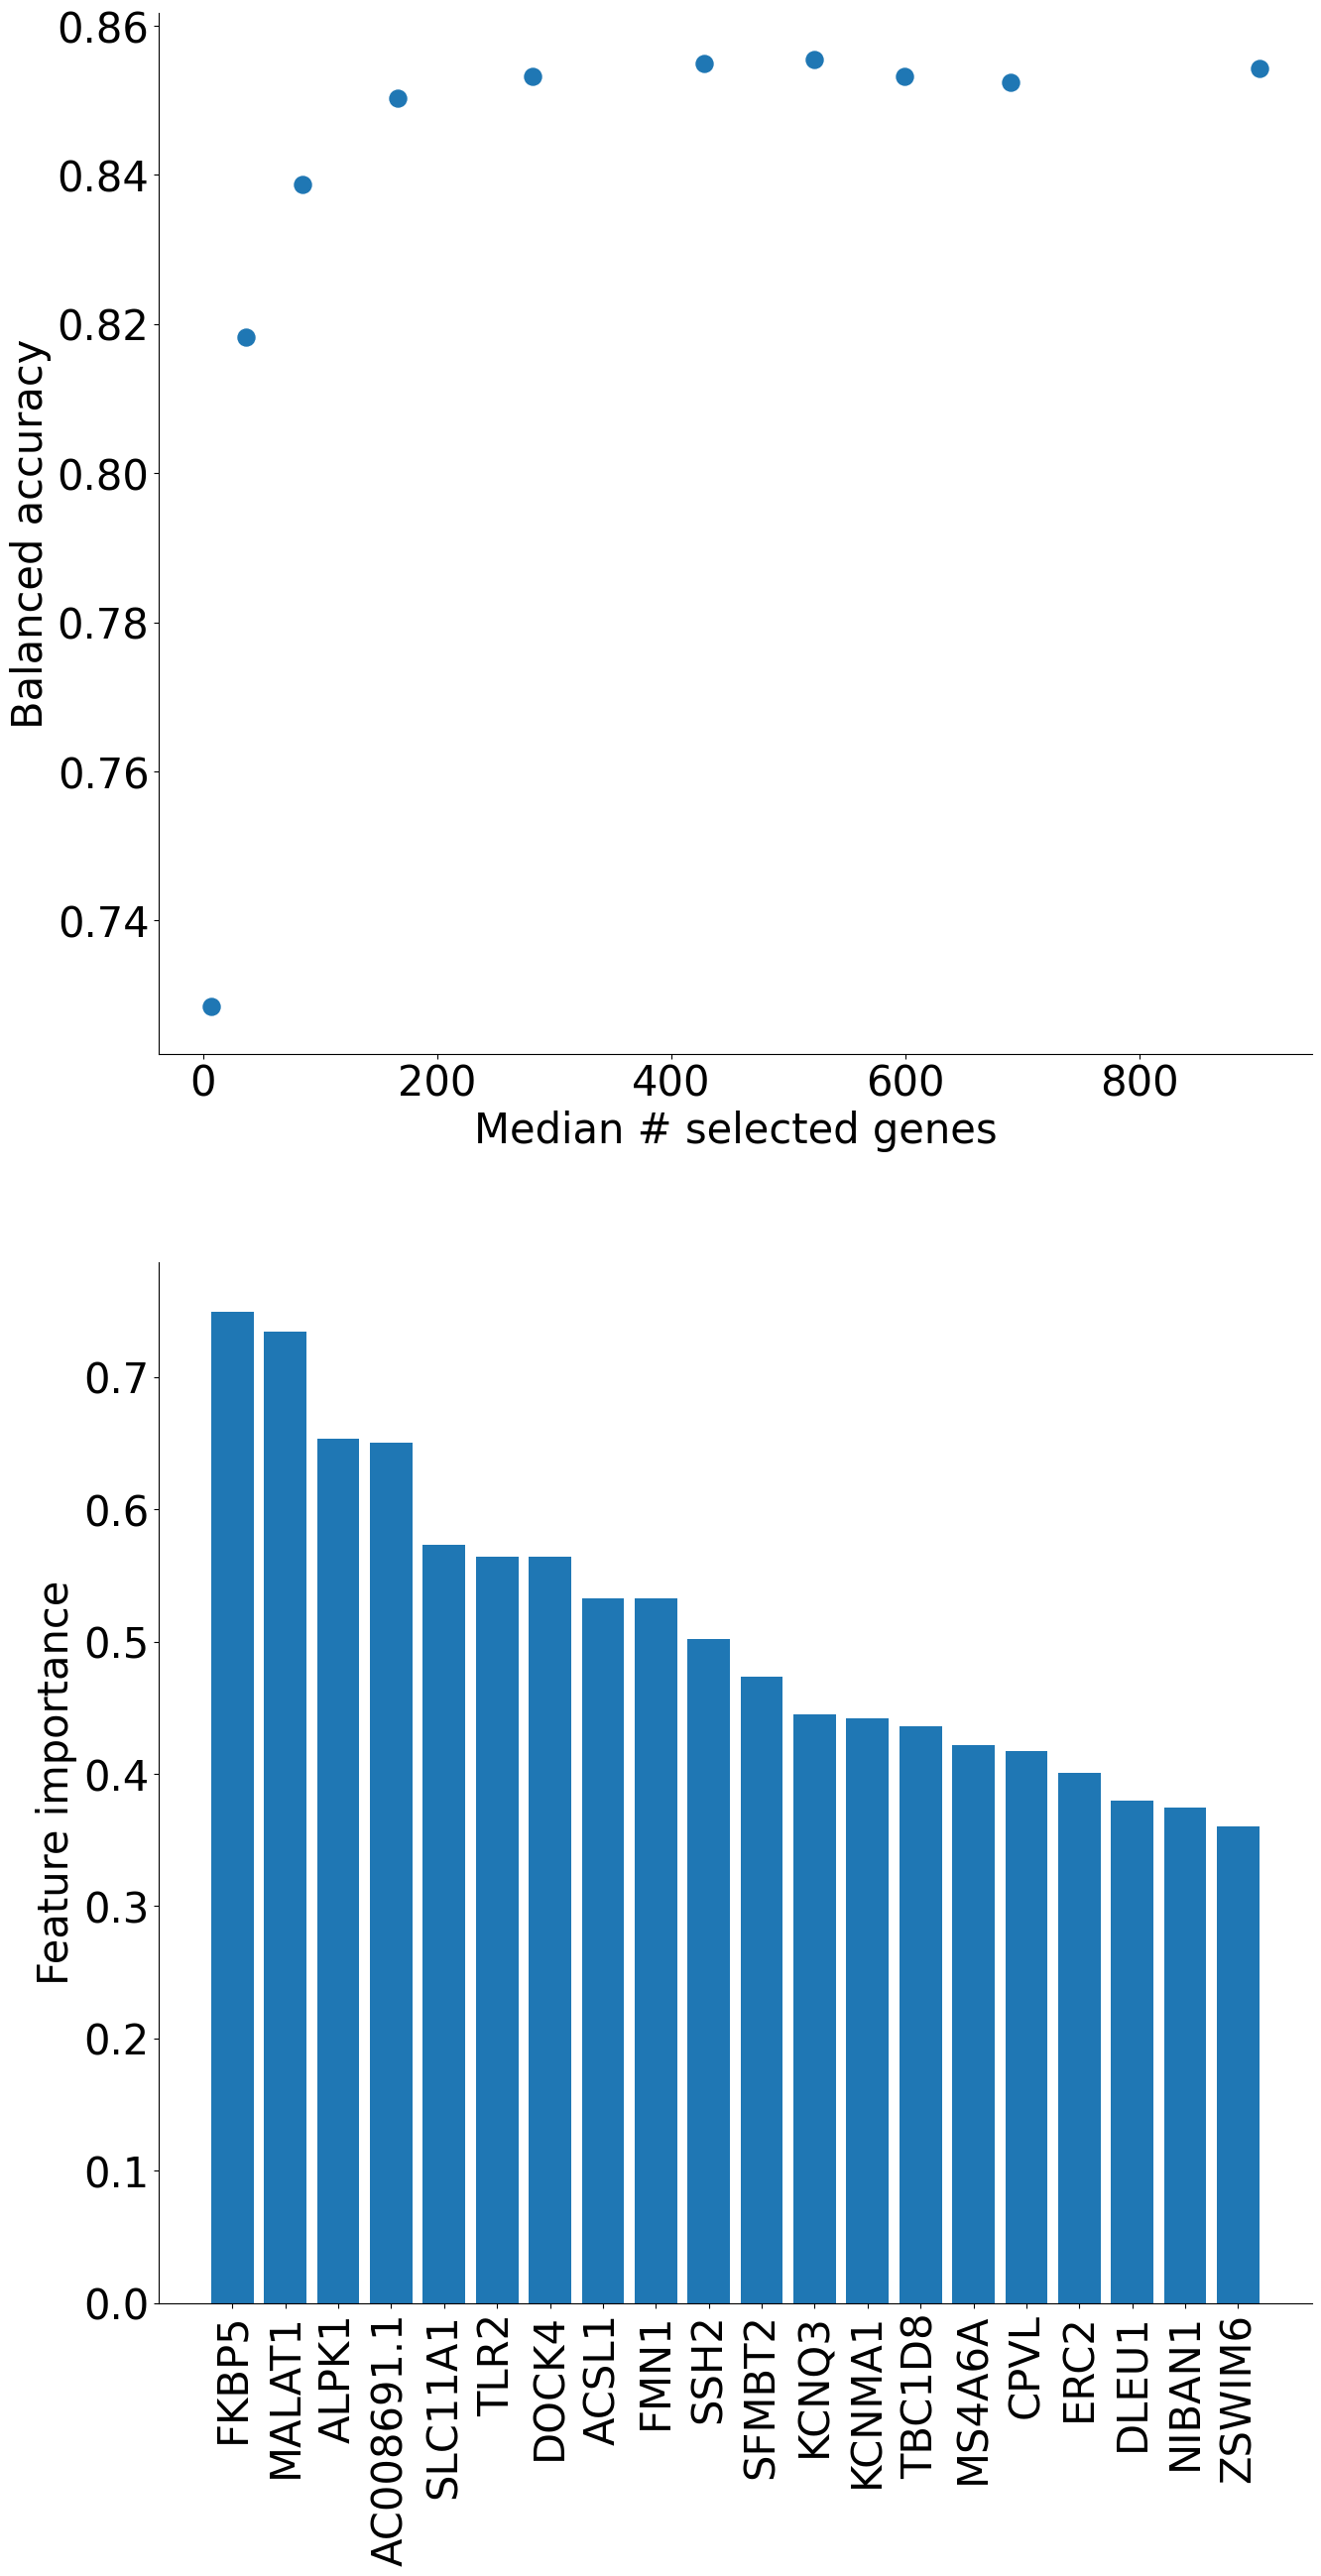

In [50]:
import matplotlib.pyplot as plt

plt.rcParams['font.size'] = 30

fig,axis = plt.subplots(2,1,figsize=(15,30))

axis[0].scatter(median_n_feats,avg_val_accs,s=150)
axis[0].set_xlabel("Median # selected genes")
axis[0].set_ylabel("Balanced accuracy")
# Hide the right and top spines
axis[0].spines[['right', 'top']].set_visible(False)

axis[1].bar(np.arange(20),np.abs(top_20_coef))
axis[1].set_ylabel("Feature importance")
genes2highlight = top_20_genes 
genes2highlight_loc = np.array([np.where(top_20_genes == gene)[0][0] for gene in genes2highlight])

axis[1].set_xticks(genes2highlight_loc,genes2highlight)
axis[1].spines[['right', 'top']].set_visible(False)


axis[1].tick_params(axis='x', labelrotation=90)

plt.savefig("./lasso_result_ins.png",dpi = 300)

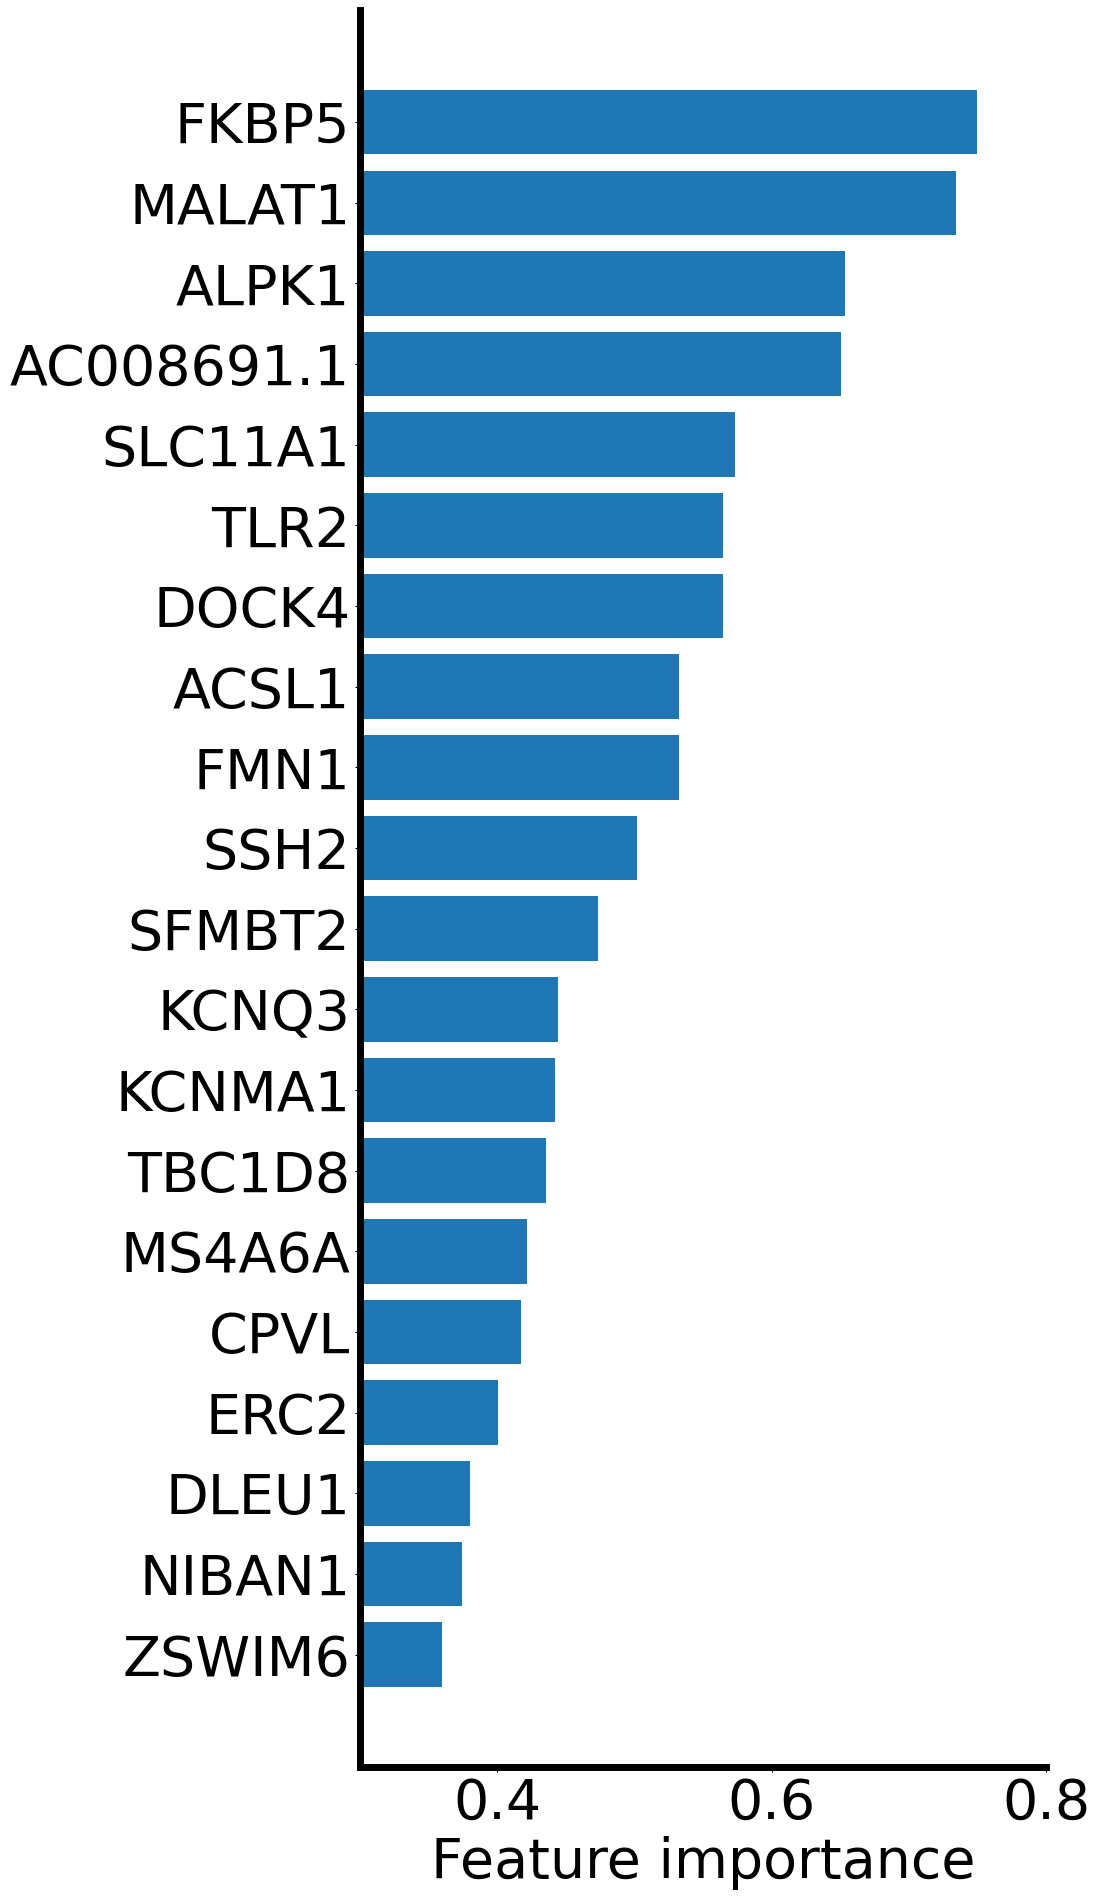

In [68]:
import matplotlib.pyplot as plt

plt.rcParams['font.size'] = 40
plt.rcParams['axes.linewidth'] = 5
fig,axis = plt.subplots(1,1,figsize=(12,20))

axis.barh(np.arange(20),np.abs(top_20_coef))
#axis[1].set_xlabel("Top selected genes")
axis.set_xlabel("Feature importance")
genes2highlight = top_20_genes 
genes2highlight_loc = np.array([np.where(top_20_genes == gene)[0][0] for gene in genes2highlight])

axis.set_yticks(genes2highlight_loc,genes2highlight)
axis.spines[['right', 'top']].set_visible(False)
axis.set_xlim(0.3,0.8)
axis.invert_yaxis()

#axis[1].tick_params(axis='x', labelrotation=90)
fig.tight_layout()

plt.savefig("./lasso_result_ins2.png",dpi = 300)

# lasso trained on ins data, evaluated on the pfc and vst data

In [46]:
X_test,y_test = X_pfc,y_pfc

In [47]:
X_test = X_test[:,top_var_feats_idx]
X_test_z = scaler.transform(X_test)

y_pred_pfc = clf.predict(X_test_z)
balanced_accuracy_score(y_test,y_pred_pfc)

0.9355240453868723

In [48]:
X_test,y_test = X_vst,y_vst

In [49]:
X_test = X_test[:,top_var_feats_idx]
X_test_z = scaler.transform(X_test)

y_pred_vst = clf.predict(X_test_z)
balanced_accuracy_score(y_test,y_pred_vst)

0.8734389170123299